# Phase 3 — Positive pairs and hard-negative mining (training partition only)
Viewer over `data/mining/*` and `artifacts/reports/negative_mining_*`. **Mined negatives are unjudged top-ranked
documents, not verified irrelevant ones.** Only training qrels were read; validation/test judgments were not.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "base.yaml").is_file())
sys.path.insert(0, str(root))
from src.config import load_config
from src.negative_mining import read_jsonl_rows
from src.utils import read_json
cfg = load_config(["configs/baseline.yaml", "configs/mining.yaml"], root=root)
mdir, reports = cfg["_abs"]["mining_dir"], cfg["_abs"]["reports_dir"]
SOURCES = cfg["mining"]["sources"]
REP = {s: read_json(reports / f"negative_mining_{s}_report.json") for s in SOURCES if (reports / f"negative_mining_{s}_report.json").is_file()}
for s in SOURCES:
    print(f"{s:>6}:", REP[s]["status"] if s in REP else "NOT RUN YET (run: python scripts/mine_negatives.py --source %s)" % s)
vp = reports / "negative_mining_verification.json"
print("verification:", read_json(vp)["status"] if vp.is_file() else "not run")

  bm25: PASS
 dense: PASS
verification: PASS


## 1. Positive pairs (training partition)

In [10]:
pairs = read_jsonl_rows(mdir / "train_positive_pairs.jsonl")
dfp = pd.DataFrame(pairs)
print(len(pairs), "pairs from", dfp.query_id.nunique(), "training queries; positives/query:", dfp.groupby("query_id").size().value_counts().sort_index().to_dict())

742 pairs from 647 training queries; positives/query: {1: 582, 2: 44, 3: 13, 4: 7, 5: 1}


## 2. Exit gates per source (all must be True)

In [11]:
if REP: display(pd.DataFrame({s: r["gates"] for s, r in REP.items()}))

,bm25,dense
every_training_query_mined,True,True
mined_queries_are_training_queries_only,True,True
negatives_exist_in_corpus,True,True
no_duplicate_negatives_within_query,True,True
no_known_positive_collisions,True,True
no_validation_or_test_queries,True,True
pairs_equal_train_qrels,True,True
pool_size_respected,True,True
triplet_count_equals_pairs_with_pool,True,True
triplet_negative_never_its_positive,True,True


## 3. Score distributions and false-negative risk

In [12]:
rows = {}
for s, r in REP.items():
    st = r["stats"]
    rows[s] = {"pairs": r["n_positive_pairs"], "triplets": r["n_triplets"], "unique_neg_docs": st["unique_negative_docs"],
               "neg score median": st["negative_score"]["median"], "best-pos score median": st["best_positive_score"]["median"],
               "neg/pos ratio median": st["negative_to_positive_score_ratio"]["median"],
               "flagged FN-risk frac (ratio>=%.2f)" % st["flagged_false_negative_risk"]["threshold"]: st["flagged_false_negative_risk"]["fraction"],
               "neg that are positives of other train queries": st["negatives_that_are_positives_of_OTHER_train_queries"]}
if rows: display(pd.DataFrame(rows).T)

,pairs,triplets,unique_neg_docs,neg score median,best-pos score median,neg/pos ratio median,flagged FN-risk frac (ratio>=0.95),neg that are positives of other train queries
bm25,742.0,742.0,1956.0,20.207125,29.003590,0.76185,0.3660,356.0
dense,742.0,742.0,1910.0,0.518622,0.581544,0.90230,0.3991,286.0


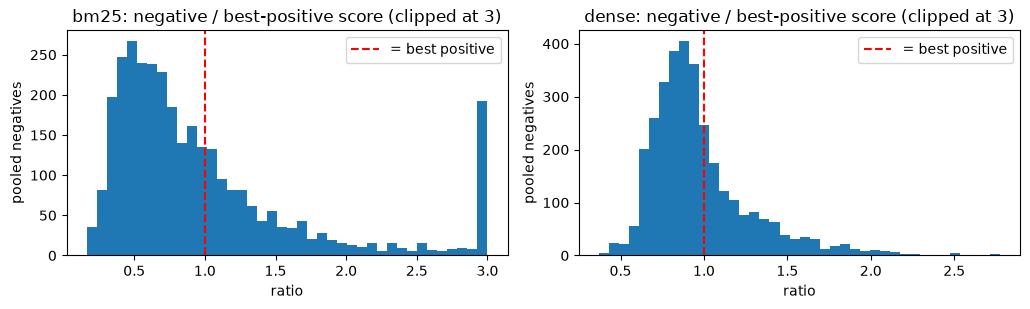

In [13]:
fig, axes = plt.subplots(1, max(1, len(REP)), figsize=(5.2 * max(1, len(REP)), 3.2), squeeze=False)
for ax, s in zip(axes[0], REP):
    ratios = [n["score_ratio"] for m in read_jsonl_rows(mdir / f"hard_negatives_{s}.jsonl") for n in m["negatives"] if n["score_ratio"] is not None]
    ax.hist([min(r, 3) for r in ratios], bins=40); ax.axvline(1.0, color="r", ls="--", label="= best positive")
    ax.set(title=f"{s}: negative / best-positive score (clipped at 3)", xlabel="ratio", ylabel="pooled negatives"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Retriever diagnostics on TRAINING queries (not validation metrics)

In [14]:
if REP: display(pd.DataFrame({s: r["stats"]["train_query_best_positive_rank_diagnostics"] for s, r in REP.items()}))

,bm25,dense
frac_top1,0.5549,0.5178
frac_top10,0.7960,0.7944
frac_top50,0.8733,0.8934
median,1.0000,1.0000


## 5. Manual inspection samples (read for false negatives)

In [15]:
for s in REP:
    txt = (mdir / f"samples_{s}.md").read_text(encoding="utf-8")
    print(f"----- {s} (first ~3 queries) -----"); print("\n".join(txt.splitlines()[:34])); print()

----- bm25 (first ~3 queries) -----
# Hard-negative inspection samples

> Negatives are UNJUDGED top-ranked documents, not verified irrelevant. Read for false negatives.

## Query 1109
**Claim:** Suboptimal nutrition is a leading cause of premature death

**Judged positive(s):** [13770184] Global, regional, and national comparative risk assessment of 79 behavioural, environmental and occupational, and metabolic risks or clusters of risks, 1990–2015: a systematic analysis for the Global Burden of Disease Study 2015; [8582337] The state of US health, 1990-2010: burden of diseases, injuries, and risk factors.
(best positive rank 19, score 10.298601)

- rank 1, score 15.551356, ratio 1.51: [4313478] Translational control of intron splicing in eukaryotes ⚠ possible false negative
- rank 2, score 14.886874, ratio 1.4455: [52188256] Global cancer statistics 2018: GLOBOCAN estimates of incidence and mortality worldwide for 36 cancers in 185 c ⚠ possible false negative
- rank 3, score 13.166467

## 6. Caveats
- Unjudged ≠ irrelevant: a negative that out-scores the labeled positive may be genuinely relevant (SciFact qrels are sparse).
- Negatives that are positives of *other* training queries are legitimate for this query but may be topically close.
- Training-query rank diagnostics are in-sample for the retriever's index and are not performance claims.